# Comparación de modelos preentrenados de Hugging Face
## Clasificación de impacto de notas de mercado para el motor de señales de rotación de fondos

**Actividad 4 — Gestión de Proyectos de Inteligencia Artificial**
Módulo 2 / Semana 5 · Temas 9 y 10

| | |
|---|---|
| **Alumno** | Eduardo Aburto Angulo |
| **Matrícula** | AL07182743 |
| **Docente** | M. en C. Luis Ariel Vázquez Piña |
| **Institución** | Universidad Tecmilenio |

---

### Qué hace este cuaderno

Compara **cuatro modelos preentrenados** de Hugging Face en una tarea de
clasificación de texto en español: determinar si una nota de mercado tiene
impacto **POSITIVO**, **NEUTRAL** o **NEGATIVO** sobre una clase de activo.
Esa clasificación es la primera capa del motor de señales de rotación de fondos
que vengo desarrollando como proyecto de la materia: antes de sugerirle a un
cliente que se cambie de fondo, el motor necesita leer qué está pasando en el
mercado y entenderlo bien.

Para cada modelo se calculan **accuracy, precision, recall y F1-score**, se mide
la **latencia de inferencia** y se analiza dónde se equivoca cada uno.

### Orden de ejecución

Celdas 1 a 4 preparan el entorno y los datos. Celdas 5 a 8 ejecutan los modelos
y calculan métricas. Celdas 9 a 12 analizan resultados y exportan evidencia.
Ejecutar en orden, de arriba hacia abajo. Tiempo estimado con GPU: 8 a 12 minutos.

> **Antes de empezar:** menú *Entorno de ejecución → Cambiar tipo de entorno de
> ejecución → Acelerador por hardware: **GPU** (T4)*.

---
## 1. Configuración y verificación de la GPU

Google Colab asigna una GPU gratuita (normalmente una NVIDIA T4). La GPU importa
aquí por una razón concreta: la diferencia de latencia entre un modelo grande y
uno pequeño es justo lo que vamos a medir, y en CPU esa diferencia se distorsiona.

In [1]:
# Celda 1 — GPU asignada por Colab
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv,noheader || echo "Sin GPU asignada"

Tesla T4, 15360 MiB, 580.82.07


In [2]:
import torch, platform

HAY_GPU = torch.cuda.is_available()
DISPOSITIVO = 0 if HAY_GPU else -1          # convención de transformers.pipeline

print(f"Python        : {platform.python_version()}")
print(f"PyTorch       : {torch.__version__}")
print(f"GPU disponible: {HAY_GPU}")
if HAY_GPU:
    print(f"GPU           : {torch.cuda.get_device_name(0)}")
    print(f"Memoria       : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
else:
    print("AVISO: sin GPU las latencias no son comparables con las del reporte.")
    print("       Entorno de ejecución -> Cambiar tipo de entorno -> GPU (T4)")

Python        : 3.13.15
PyTorch       : 2.11.0+cu130
GPU disponible: True
GPU           : Tesla T4
Memoria       : 15.6 GB


---
## 2. Instalación de dependencias

Colab ya trae `torch`, `transformers`, `pandas`, `scikit-learn` y
`matplotlib`. Deliberadamente **no** se fuerza la versión de `transformers`:
hacerlo obliga a reiniciar el entorno y el cuaderno funciona igual con la
serie 4.x que con la 5.x. Solo se instala `sentencepiece`, que algunos
tokenizadores multilingües necesitan y no siempre viene preinstalado.

In [3]:
# Celda 2 — dependencias
# Colab ya trae transformers, torch, pandas, scikit-learn y matplotlib.
# NO forzamos la version de transformers: hacerlo obliga a reiniciar el
# entorno, y el cuaderno funciona igual con la serie 4.x que con la 5.x.
%pip install -q sentencepiece
print("Dependencias listas.")

Dependencias listas.


In [4]:
import importlib, transformers, huggingface_hub, sklearn, pandas as pd
print("transformers      :", transformers.__version__)
print("huggingface_hub   :", huggingface_hub.__version__)
print("scikit-learn      :", sklearn.__version__)
print("pandas            :", pd.__version__)

transformers      : 5.18.0
huggingface_hub   : 1.33.0
scikit-learn      : 1.6.1
pandas            : 2.2.3


---
## 3. Autenticación en Hugging Face Hub

Los cuatro modelos que se comparan son **públicos y abiertos**, así que el
cuaderno corre sin token. Se incluye la autenticación porque el Tema 10 la pide
y porque en un despliegue real dentro del banco sí haría falta: para consumir
modelos con licencia restringida, para versionar artefactos propios en el Hub
privado y para dejar trazabilidad de quién descargó qué.

Si quieres autenticarte, crea un token de lectura en
`huggingface.co → Settings → Access Tokens` y guárdalo en el panel de
**Secretos** de Colab (ícono de la llave 🔑) con el nombre `HF_TOKEN`.

In [5]:
# Celda 3 — autenticación (opcional; el cuaderno funciona sin token)
from huggingface_hub import login, whoami

TOKEN = None
try:
    from google.colab import userdata
    TOKEN = userdata.get('HF_TOKEN')
except Exception:
    pass

if TOKEN:
    login(token=TOKEN, add_to_git_credential=False)
    print("Autenticado como:", whoami()["name"])
else:
    print("Sin token: se usará acceso anónimo a modelos públicos. Es suficiente "
          "para esta actividad.")

Sin token: se usará acceso anónimo a modelos públicos. Es suficiente para esta actividad.


---
## 4. Carga del conjunto de datos

### Origen

| Archivo | Qué contiene | Origen |
|---|---|---|
| `notas_mercado.csv` | 400 notas de mercado en español etiquetadas por impacto | **Sintético y declarado.** Generado con `src/build_dataset.py` |
| `catalogo_fondos.csv` | 484 series de 59 fondos con sus rendimientos | **Real.** Anaquel con Rendimientos Históricos de BBVA México, 08/10/2026 |
| `clientes_simulados.csv` | 150 clientes con posiciones de 5 a 20 millones | **Sintético y declarado.** Nombres de superhéroes y villanos |

Las notas son sintéticas por una razón que conviene decir de frente: las notas de
análisis de la mesa son material propietario, y no puedo publicarlas en un
repositorio académico. Las carteras de clientes tampoco, porque son datos
personales protegidos por la LFPDPPP. Para fines didácticos y por privacidad de
los datos usamos nombres de superhéroes y villanos, ya que les puedo simular
características individuales relacionadas con la ficción para poder comprobar la
lógica de los resultados.

Lo que **sí es real** son los fondos, sus categorías y sus rendimientos, tomados
del anaquel que BBVA publica todos los días.

### Cómo se carga el corpus

El cuaderno busca `notas_mercado.csv` en tres lugares, en este orden: un archivo
local, el repositorio de GitHub del proyecto, y una **copia incrustada** en el
propio cuaderno.

Esa copia merece una explicación, porque a primera vista parece una rareza. El
selector de archivos de Colab no es fiable dentro de *Ejecutar todas*: el widget
no siempre alcanza a mostrarse y la celda revienta. Incrustar el corpus
comprimido con gzip y codificado en base64 —son 14 KB— hace que el cuaderno
corra de principio a fin en cualquier sesión limpia, sin depender de nada
externo. Y para que no quede duda de que es el corpus correcto y no un relleno,
la celda verifica su **sha256** contra el del archivo original antes de usarlo,
y la celda siguiente comprueba los conteos de clase. Si alguna de las dos no
cuadra, el cuaderno se detiene.

Reproducibilidad: el corpus incrustado es byte por byte el mismo
`data/notas_mercado.csv` del repositorio, que a su vez se regenera con
`src/build_dataset.py` y la semilla 20261008.

### Por qué un dataset propio y no uno de los de Hugging Face

El Tema 9 lo plantea con claridad: las métricas que publica un modelo se
calculan sobre datasets estándar que no representan el caso de uso. Un modelo
entrenado con reseñas de restaurantes puede tener 92 % de accuracy publicado y
fallar en «la prima por plazo no se comprimió». Esa frase no se parece a nada de
su entrenamiento, y es exactamente el tipo de frase que mi motor va a leer todos
los días.

In [6]:
# Celda 4a - copia incrustada del corpus (gzip + base64)
# Son los mismos 102,590 bytes de data/notas_mercado.csv. Se verifica
# su sha256 antes de usarla. Si tienes el CSV a la mano, la celda
# siguiente lo prefiere y esta copia nunca se usa.
CORPUS_B64 = (
    "H4sIAJVfyGoC/+VdTW/jSJK9L7D/QfB1vAWRFPUxe+qyXe4C6mvKUz3ouQxoieVmQRI1pGR09b/p4xzmsOjbXv3HNiK/mGSSzEyK"
    "ScleoAdTVbZlZjIyMuLFi3jJ6vJrvPwluvx6iLf7+HK5jvL4H9Fynzyml/v41316mWx28PcUvm+bbuB/l6vka7I8rPcR/Gy6XaX5"
    "P7J4HS2TdBvBX/7zPz6Mx2Pv0h/70//yxv81Di8/ZfE2j0Zfk220XSZxFl1ex4dVNHoXZQ/p6NM6+i29vFmP4LtWySaB50hHq3g9"
    "uk+36Sga7bM42e6jUfT0P2k+yg/3ydMfI2882h3gG/PRPTzw6PvoId7GGXxhk2wP+WO0fvp3lI/i7WgN30KfEj5ztIbfGI1Whwwe"
    "9+mP7avLDze3P/z17U8fYVFZTFYJX1lfXrx+/dMPVx8/X47wD9e3P1zQZfnysj7H+QE2BD93E+cR/B0f86coS6L7dTz6QLdkffkG"
    "9vSXUbL9mmabCDf2zyNY7dO/YbXLGH86i7/GsPhlEtFnhJWvYb828a/JMtrCyh+j7W+wtvBVONql2WhJ9whezAG+b5WSf4QNy3EF"
    "8OV0Cw+Wvhrd4UcvU9xS2O0sfkzyKMPPj3/dpXlCtoD+xny0jLI9vJl8FIE9wKuN8leXnz7evW3anM9vbunmfP6J7U1Q7M388kO6"
    "J4uJtk+/r5M8ydkrv0qzPX/l/HvWEdm/0rf/GYwDt2xNXxS+9u/REk10BEaRp9mOWAtsSrSG/36LwATADjbRdn94RPPZ7jNqRVm0"
    "BSNL77/FuPWvcOvjfx6SHX4VfsNjnOXwmmIwjyh7+h0+5OHAjRDNJ4J/ydlGrUfrA3yntDHb+IG8ZXom+N7cfnxN9+bL9Vu2OZNi"
    "c/zLq3Rz2MKrhTeX4o+Bjai78zrawutPyRvM9rBQeJR9RLdJMhh4Rj+Uz8J/k9eJ30ksHm0/xmN0gBXAoRjlyQMcdfy5bfIYr2Hh"
    "0T6jBz4f7aIsqh6ZBHZrFf/m2pzojr17+xe2Y2GxY4GROV38MNrF+ETEd+AaVxHxJKN4s1vH6SUeEXj8HbxttCP4Qh5nj/Dc3DfI"
    "BveYrh+JeY3A0tBCyFKljV2SX73DX/3qovAjcPhgO3NwpSWTuL6m67t97bP1TWWLaFqf7CEvwHLJaxkt4wxdHSwHzg0ed9nr4cd4"
    "r6aSo7iEfYHDAN++ih9jPA3R8rA5rNH+cK/QsVKzQKuA1wamhT4lT9Ao4GCtJZc5+nYAm4dt+Ro9ptkrdkzRs7GDCotY7g/ROvmN"
    "nCd8Otz3BD+WmztsmDCGZfI1i/6xSX7dR5ebeJVE7Ay9+0R3DLww27FZsWOzmh1rcr/whPEmAZeBNrujZ+mwT9bJKlrB9uE+RVmW"
    "3EdkM9B5wm2Fy4bD8Qjfmx9GDwfcWHI4irXwrdMY9k/MTb55x5Yxl/1koyuQ37y4aBJYXErvmwx/hrrJJWz2V/IZ8Hy7Q04cF7zy"
    "fBfjsY5G6KXIH/BFkk8H44V1039cFTfH91G0ekyyPRp+nt7DIuFrxE2Qrd5Fa7jAI+od2+9OuDKrLnBRrNtT7s4jzd177uZexBrv"
    "PtH98sZyrGHkINrs5C4Z3ScxeTjcpAyW/LBO7+H2pFuRkMgMdw/d/2GVYPSFfny3h73IUnIVovfMxHU4yuEv0Yo7zzyG2zcqrbXe"
    "F77nzr5Yq9dmG5WD/Racd7blp/vih8P2n4eq945zuHNSOFkQCMArWsYYKlxSEyI7Am+NfADu0zL6DubFYqh9vEGHANcl7ncOMcc6"
    "5rawefod/EWWfj3ABWjg9G/esxjp6ge+UCmAnDTGxaVbre2lFmuH6ypiPg3Ws7nHbyb+DgIDXDm+1GSb7zP8rD298KgreDjc43bi"
    "P0frysVGvWH2SN4/+MFyhI6HC57D4I3DrUc34q83d2wjAvl6r9mIBKOLHJ139EAjnS3+zocsWtFYiHs9dg5TWAXGyt/JS2ThHdkJ"
    "EkIddiQ7YKddG8F9umIW+pF5bW8iW2id12YP3Pa6bpQny/EtwClakpym5MZY9PkNjiqET3Dw9+RFRyRgxSXD28qSOH/gB7ndId98"
    "+VxdUigvqfkVwFPfw7+hH8aXu4Yr5n6dLKlHhreA0SBbKkTp8PJ5fARvBH1HXhhkLu7QHbyNX5NNCtldAocccjx8/C9//fzDu7qn"
    "5+8DVsEeftp+kFp9xhW/wPm7gWsUg98MnSBccnDLsOwsl/wEWdUNcSz56Au4FnSP8EHkcKDff4jIr8cgEVd9qAag9A7B5yFZyCZ9"
    "FIkGudbAq+9JZIoftsachZy9FTeFLH6gSWtbvAGuhvmczzdsq2Z2F682LSvFG3AqNyk5O/RYbvGnpdOYQdqV0S/VhiTovzBri7f0"
    "Ms9XJOggl/QuwuxWn27xUFHEGt5cto6a09pqHvBuIGKIMww9UrQQ+AmSdZI3s4QVoe2TV0KwE8wQ4KjsIxI75DR7B8uBY/r7Hn6v"
    "ZCYkBLuPvkVHWoA46fU78vmnG5ZuvGEbspBj5xb3BU8FSRRZa9Tgl75m5BHxsnj6Yw1pEbF2TAPRPayIwXxdH77RA8MybBYxsLSw"
    "3YQV5+uPNWgSe/h2yx1oae6ONuwH3ZhPV2xfPPmtap2gyIguahwgCyUQMCFJUiw8M4aI7Ppc43rgj/ATl+QyWtLbtxRBrWLYhyQl"
    "8Ev12Be5hkH4BCkTz51u2YJ969zpYrDAtw9kySCUUpydH8inwwhbuqiBJM8jljwWZNJv4Lu3f2Gn6Of3bAOl2G5qcEHCe35IwabQ"
    "lOC/dfqAZ2OZrlN4IJJjpLgoDjlyK6GxEf6NWhhi0fB/30cEscS9T8H/wFVBcg+SfiPYdDzuprksaiwqlK9Pc6RFGzkUOAzDNAW2"
    "Qk7MAxyxtIgRSQzwHT7isCXOmvgmfKUs1kS72pYdcY+bVQtSvitj3v7UNp3DOBOcxTohYTIGPvCgYG15shU5wQFzzO3TH/ke8V94"
    "VgL7KugT3R8SUVCnTPyICKx57FlkxUfHHDQ8h+9bJeyNSwgGWA+7tq9es90pAXb150remxsCzyb7p3/RXC/H94NgHcRN3w7wlPAs"
    "4HUSglWPIv4QsHeV7H+Lucoq5uUfviU5/uJYfyAEFiPAaH/epe5z8Q5e8SN+EU3te4yOb/xqVsnxMF3lOVABXW3AOcAXU3yvZLkQ"
    "tYAFR7Tm8V2+fOEqIjlKUQsxwJuU8o2/kK9W81iCnGq8G0kqIB/sFURlqxgBPAi7SFDF79/vaGtfk2xTl0Puogd9yK+gqsFYb2tH"
    "lBvLJZbO5caO8KFllTLw2oHyM6nE6d4xL5mIezrwZcxIn9UVB1Eqt+INklI8EA7jRAVcWFB2yd8Fg8bFUYALH8wa1gK/GC+R3dO/"
    "slVCY4/2y6Ny4oKgLexoBz0xl8nSxziGHJzsLV8eC23FnUkCLbgDmbXxgJ6EZrwSll/ihz1k0QZTHHLPgPthZa1GSEaAm18YpBdM"
    "2it2jW/nWaQeQahHUerKtxQsI4cbTxe4C7ov8GKe/ne9Tzb4t2UiUotdCr4EUQOMIiEAxNAbnvzbAUJknnCwC01kHq3I2c/vGRTw"
    "hV3LwdQu3K1JFkVphjsvamlgRWS7U2pEJMlm0dcm3qcriJAfWLAHLvMQiWCsNptoXZZaXwpmJl7PtKz2wmL8mu2ay/Zcs10MU7lK"
    "STaXEbAarW1dYa8IrCRaLylNBSyB1gxJvSRa76W623deTieldVzNiv4iefshoogx/AHX1A9fo7VSyVEVgS0HC7k0b1CprMOTo9Hy"
    "kD1KpvCeAk+QsmAdAl8fcXhL4vBYkH9ZwZEJrLRL9iR2orEs/kZuV3KcV7cynti9/8xgwMm49egXGGBbmUINYV2UKTjGNfHOHsrV"
    "5hNsSR+uWToxsa8Cno7bclTSqL9p1bRxEmjqUuoBPIvTxl3sLa9qTybdUqp6d8KxE3jmx3RJ3h44WljGBn44GqUQhG5JtIBunCSE"
    "FGNQKm6YuaStl2sRqvL0ahJ2495c6DKLEyXIfWO1DUl2NUudGIRe8rGvgWlJoPCQYHBMgNQIcdp8hKFiTqmBcBIQRYMPVkl8JBdl"
    "LpqHnxy+dpCbisMtkJTJTOPO+SUk4/bgMBjdcc3Pbk7eN5rE8hfG7CDFHZ52wtGApcBRjiEhVco60i7w1TvHndU4YzKXrcHsGngm"
    "hA8Bsot4c7KwwpTL1/i74iqODxmcefiDSOTr3AZ/u0XuK65ryvLDWEasq7602uYY796y8CQcW9NU213iCS/6rtw23RVP6dB/urn+"
    "csUQqtCz5raZswHLpuCUDXhcaKS7PoT3FPF76Ntam7vrwnVexkmCAv4LA0MOw9BXxyB1X4UUEU40Zd+OMVnhgOS8TvB1YAV/i9br"
    "0R3sX7wvUSoRG1nz88nBYDyJCmWCx6bxr7DU7Tc4oCZboIRTYahP1EvFt5JzJBA+Iozo5pDlSRxlhRESbcH/FagFhSwgJMB7H/cj"
    "F/W5ijdttW3RICIO9rSd4WJTYpq8mg8RQbtiQitF1rC9jNhCXApe+b2ze1w2wSgsx3Bu0iQim3gdXHei+s3tawY/XV+z1SxsEdph"
    "yTu9XOUalEOAA9NxOzjQDMaltCACj3DYsnfCbjOVDaCSAFQSax/gczNOX+WsTT1N0nNOXL7W06pAlVNfXpqJfTdXoSGt+Y2VoFmx"
    "MiiXoHkksSENoiwikS4m/NVgH8tkuU5ZoIfYV+7Wg4litMj7pqW2UBMwvcaDvRQ3oJZhprq+gqabX1O86tBdXDk/uu5iTTtntX46"
    "tUMQy/m/pgEOvowvZPQmXpGIbotvBgL1mJfAV0lO0hzaHVLTAsSsqSbO0d1ygm/Py+DTqW0f9IXSYVGQ6nnhmISY3NzARpgRb8FW"
    "4809hnVrWl+Ez0bI455BQxiQR1n2nbz6EjeFgkE1YH+PuUxDc83fP1ZaO6clVPCZ9H+5w0tY5vvh7ke2PXM57Temn2nyvKFZF/3Y"
    "lpa5UU0Sp4t2rKmLg+2zHCOOsNM4TMmqZmOrbSkfuvqJFuyC2MfLbbp++uMB6S+EK0XhOrxnCoYSHg5meLlkec0N2a4aK/70+acv"
    "d6w98eY9u61mXldw5R2/X+nu0M4n8laLVygdNMYEYre16EC7lAjBgle4I+xo9v6Z/SGH+HuasaPR/Pqrp2Lm2w5owVuKO0/k5h7I"
    "DhzQ18K1xc8IBdjQ/cK25JejSHgZ0VgPX4TTTtihkH4UfeYbEvilZRZz8cKPL0S30pdVFvws6FjzrMFk1NbOZ4rJ8HBuNulOXqwn"
    "lA3AZ+zJgmrPF2u4u7njGxS2hTS2FFzzYTDlwUjuhsF0rBa3JQ23X15XusRnUw1IUpdRnwszUVRtZjMN3cesdXw4yp0DJoACbc66"
    "tVS0z9JitQe4PX5fIl1rQw52cZVSxg8NRMi1ypJZ2qeM5WRWCoPPhpAWwxH55tC1UojLddHOYLIYFOamvWKIIVjqnTEf27FftOQh"
    "6gIFB1dCraV2Kvr8JY413v8sa8avgvXEkTBqHqasimRRbwNiwIUgusy9PunIsNa7GOmK8Hqom/oxWtI0wWgaQ93AhVKImeGwo+jI"
    "49/oEwUsKHzi3G8r6lgw47phXZXK0HFY109VOw/aceDzK+Z1oLLNJ5pmHMNb7eSjRRQYfx5qmPF2g5fOigkuyk/zaef4vXWxKUn+"
    "wAbhTij1tx5KvRKVJtbvDGWilA21ZkUcE/lu7AOFwIfm0ikjkbQmdpx9LSLz+czuGjppy65x123xZud2XbdmpIhpL6SInoaeNN4w"
    "MsdsvrCtnZ+qTs7JILxOvhi30VraJxvVd+s883E2HBCHLJvtkGdn4xfdY0XCljeNE/uCqOrvYFE3Efnxwu+Gbbd3GLiZkukCMVBC"
    "r0VgCxgMGVm3wgbKvNPF5IiK6YUm7HKKton8qh00E6VTEVQuwvaBRs9kSqg+nFZb8xbTbt3TDYSvU8xkUHCQxawN43GHgYbDYKCt"
    "rkkEZoWznpt0/VV80y5DzjWaLe3P4Pf2Br+AR5S/R54/EMPcYXGQT58g+0lTEGrPcIXvk4do1UPPj2aiUOHLFlbWrS8YnPHUV3EO"
    "GCPEG491xPVOQXkFGnDEVBaZIxtc7o09u8LG2ZUuzAhsLBj3xr7VjL2zIae47dr9cP2Xio0HRwQrDfNYzwlIkFkCnJfjjSdmMxQ0"
    "DfUVMNK6od5dVl3FxrxxqNOxMEP9RP6wJb16CZIepDXIUTPHPMsbSL4PoTOc9YX/FDd1+7idelblN3vjaRtXy3K+d/e0VSIG9lTi"
    "4OOYeDzjlfUYLDgyxmMCe2p176lVzYBcc8t2Zu7kwq/I/zi48Cl+VmpN8saa0M2YsO/UBboc+6iMTve8saEbbMDjhnR/Og9WszrP"
    "bkBUfZSDriol5D8S2kSHjdRtTdMajADpa2QDw1PMWw/fJIx1TTZDtEiIqXrmyjtK7dHzfI32wHOal+u2YUHUtfn0MM/rWtx0TNNw"
    "C71Wh/d53kSDVHEHoKlYv5jpWTz+kVUlpj22JZ+MV+uQNFgFzDxZ1cIzm2/uHCPSgT2Fmg+bP+p5M6tm5nIuqA8O82W0Zv178A6Y"
    "OYvKFvz5IV3vYnpCyMxfdiwqSh6wF9t0Q+e2FgemHQx5Uy4le97cpOOvEueltJ8ik0z5IEL5aLVJtmRcA4n36eX/C3wzyw0ESQBt"
    "9emPbBVv2VjIBrCjxf4E35LDdJ53zJCWi0/CzPDmY09Zuh2TzQ5SkWUCzpU8sFBZoWEc/AFOImQ3dKYLLrHEgBhyXI+C4vndq7Lu"
    "eyNaMa0Pdz9W/Izvtb9nMUmjnm5JWm/ZJY7PinAUf1GEiZRsqQuuDevFgF1SgGFVFwZpkXwg4jwlFgOzU7DpwxnzWLGhwlphqXqy"
    "4ITfV3vmMIPwnYFCSizk2wwyNkQB0MrYogiNLeeD3dN7gn5gOniAE5X8JqzlAcwI/4Vza1auRXaqBFdPFpKYmDaADzpm1k29R6GX"
    "eX7YERu6aA+YXWUOffQl2pHEPX/a1hjfftO2pqPnVRCTgXNxlc7M9Jwa0JOzUaMTiElZH8JIB8SRuvWxJJsmV1cpApbVIo4bdVEr"
    "uBD0JLjgEhdU5rN5sgpFW0FIR85RR5tMT6rA5smSEoFZYmoz26RM2Og+28SwtMtvqcA/Jt1xzaKixYtWBOH6bSVJCQIT7rpmxOyJ"
    "eLDi/QgvExiCbEeVHipVFfvSg4NuOaXuKqtPWEmf9BRHO5YnUCpowdT2ftHiRqdFyURXqMBaApuZJ5oWQVwFOFTMH9HDcih5TVvx"
    "k020ZAFtLDi9FEpgLUGQOETgibB1AY4HSedLXF5cbUJcQBEgDZxbBfMjeDi6GnsMi+cXZz3wAj9ckf5NtnjyauRYGoWD7Gaue2UZ"
    "Crsz774lzgmdW9mDydhI8LOrllV9nb0iC3WG3S6iLCe8iSyT4dllk9rbc4DuETe4BGn9ogko2yW/Jy7DWRbwebAgC2hMzIJ1jYN0"
    "zEJ2eZMoTHtvMmklsLYWbp8njU8p0k7CLohtXX+yumhXch0OB60riPZkajufHoMw8FZfyUHLImmCH61Ub/EzGMslomhkktEvyePS"
    "xJhtxPIwpYq3tCiQr2JRCdhFeC/r+wqrE408WXxjfpRIpprCz/oaT9rraIqawyDq1cW2zDWUhfPIM11CWaqHWNgimrVdGicTs9Dz"
    "wq6vWPX7098/0jWHY50dmKAnZ6FiLBM5RYwYeh1nzTbrp84G1E+tYgShb0u+qG97PYm27VVl1JUXBhbloC6K6y56eg1nALNbVVas"
    "8G1EDmpBjxrlsMmZjUrhhmpZDK1oH53vSI2rzzdshVNbRq1Zq+cQ4rmuuwOKDrqPjEIbzo4oOzT0SgmGYyyxqiqMtwqAJfLw8qQZ"
    "kpUeqlc17WzG59EUWT5XBiF6oabt9VSEYXvOb7iwGwqrnZlrIms26UfWzL1cU3UCpjcdd5rw55rt0X1qt521TL3WRjDOsKs5z8PK"
    "V+mpkArANLXXr20YU8CZTARgYh1dVzHeTNHIn5NG35xCTWvSCFYKWcrTyfG9rfCj4VfnsNhkFdUoTmEfRrI/UGOLdXOzBO+Bu+5p"
    "YDvV7wTAQH8KH6a1LK2KRS8ZtFPhaYX6KQtWzM1Q1AYjPzdgSO2IKmtWGGW+DdTgjjoWZD5zjxoWfYCFDagaJ81zvWpvajnl5OL/"
    "RecYVYCVBrJ5soqFZ9M59nwUCT1ZbGJqNOPlxLwF18wOZRSMNxvbUjvqSzE2bMJZT2xCdxWa6tBwb2Y0P1j2K5oa3nnAXDMdaHca"
    "DdcOQfAssMpr9Qxu13zCr/F91tc4hFZW4t3bq0oqODMk8tUFEAlu3GOyTUUbEPXt/L5ks9gQ8Fmh19ozU8ZdipCQgLiQwJi15eKq"
    "Srs3s59JN8zI3561utoIzqK1UxZkmJ11g6DD6EZuaRA3/8xIpfbCpnuuvbxyvt1zgjU+mxu1M5eD45OVDI/vKW1vhJFKclwlwJst"
    "DEvPF2Z6qGZmNenZrHrcOMO+zLKUhKUfGhB2bRm1IzkRUUeZe3appPlsPT98vrJAJIWQM0lZPMKzUgT3XwXPWhHck7UlzEH1JmDq"
    "FLRx160ECod4PrG+hdqdLVnBAxnSQBCWCHcmH2HBMWdcJhSbJQmlekbk7IMXMVnQ0poiUkBFHsUzD82ktK0UOE4XcfPEam4k+mWa"
    "+VqMHx3IRbqRsZShSdGGLUtd+H2ywgcuObvVLOcl6w/XLCqbz23FMTVHzAarKk/B7YxVmcFNhaUsbEVvelxyT/Bc65JV2udi3GXY"
    "UqmYszvk5ITWVmrISE78BHA82F5U0UPGgR6rxyTbE9fJRVDp6C/cejhYYG9RH+KnZhOeBfQoq2v4Rzvgc5p4RGaYypHkwu8sPH7i"
    "QVXDETru3rKLeRF0V2k30iJ/cWOy+cCwYgsnJpmLYWn11MjoIjRppKlfTFudX9W867HOX7MMXfHbmo93DviCTMDl0wHKehzdGdOD"
    "+nMHcpR8lLXIpGRpjsCCo+hIndXREJcqL3mxsNaAP+GkX8euWokP/fG41VcbNcCcP8Xt9jUL/z79/J6t27Ojubo+Df3ky2Znwh/b"
    "6NLaDBnQXQlldapjmL4u+8SEZBeHrP1xYJ1F1c+wOA8VNp4Y8xlBvqzxcQxdZcgxf8bDSHjK5491LSomWCK8xOiBwmmk8+0BvBYF"
    "3HjSzO6Lgu2oNsYjeLojyT/TXHNOZ60yO/yxBoDUFJdGsEfojEZv4lXMQnV48gOLbok7zAlCTDegJpthjI+a9iMtt5Mf0Ou33KPN"
    "jiiV6VHAgVuTjo0GGzuaKsmuP7ZWa9MCAoPzwHttpda4klvhMBcmfJmqOuuZR0l/vbkrNwv7sgSIiQzaRXdyNCNu9UiP7pE2ZDjL"
    "zfcsS9s1t+jZKck5LUsIXJZzJ31Zt2Qo5qzXE3PWwZA8wU7j1GLfC6wrvaeu5YrjMbFlGdbjalQLl28tDTd2WUruj5QaM4HZmJ1u"
    "4n26Apf6wKJueKGHSJhtbetBa/ysjET1ZT0Qw/xA5v7yPJFFRJS+npBN2aeUI3hYJTQ8XkY7nPBLmYGUIS881yiHv0SrKkuwazOg"
    "ji2stNj4srRHK/G5LcI+N1K0Aqb63kyvzN7ZQ6lTZ/xwyMGxAhqSdT/mfTEvHA2y7kf+0ICb5HsLi6lSVYnfGobSkHRhV45AYPCc"
    "C+/LOiJGApFa5mfHsFKSiOwlsDQPCsU58rtOpNHJahlPvazUmnRTL+3GV/qyfIj9xIATih3VsVP9ss5HD7SYAYIV19M9FPUrXxYB"
    "MZucVef7hpyA0rY+cWZF4uuHhpT1M5IA1sE/ylUmi3NMOs2ukOdktcsgWc/J6qsSZjCzyZelOnqZGVaRMjh6L/rrPWjdDl4f8u3G"
    "UH/QNPwNsUPdB56YD2Pz/YWt9FHtvMBzFpJV8YZg3H4htoe8bf7xpRKiIArm/oUFFUEpBDQiIWgDYhpXsF4o2qREHl3CrNRGqGJA"
    "HJ2RILqgVpIAK8UfYNWsOEVKE6TMQahWAvDCC/cBokzKYe4bc21SaK/22vs6gZPzGPnaGlQrw2b8IGiHQZ3nDGcxKb96MclaKYHZ"
    "ORoMZjPQma7OKvaDUDP/oDO90OkYIaWYLCuZ+NZ3hOuZAAIDMOzov+JncGbbo3PKxt6jI6Amq+UNN4XVzs1asup6EytQRC+9ia6H"
    "aQtz5z3fflm15NjMqXZo9rnFwtWcaTLuzCY9RUemdUelP9ExBCUzd6qYMORIdH/it07PL5Y8JLLRwxa0IiPqLgRt57tdPePEHQzV"
    "+RT+ZNJl5nY9ffElKTr7k9CKASeNaqN5K1kOkdGSVLRgWZTYV2LrSNO2SynrKsaRrWkmEn2JBFU00bm72xWEYzLVaAcNxy1w6vcE"
    "1Yl3R/gmsiHaYa/nMfRQn4l8+vl9hZoxmbd3zZyfXI7NjHruCjuFbTod2+OVJ82VI9lCZBEPv3P55SxEPOpa+v3Q0xMsuo2ImYXP"
    "nzQnBg7yCUt+6HctYJipTlQmypzPiQ4Dk4NQAoRuiggMTf5AduaAwDPEbPyEU5NALBq2K7+EQ8yvfBH3whfh5iVNP8kqLZrbN+lG"
    "oIqCqVKENPKQ9fpoVG3SCjXV1uF7lVwzrpVgLQy7CSyc0VAgczlYvuZpG4mm8UjrWrQqZ1utxDkRtzu6hKnXt6tu38yw3ac+13mO"
    "XT5K8hfObeP5fkee902/Op7C1rBxf//IA2IegiwsB55rO2PIFomOIWn0cNHCx3awRHbBK4JtIX716d/bWKgvi8toVeAKzsQ/1HaH"
    "6bijYLt+zmMPcu5u5HaVlLksgWLG/e6ruFtG010Wdy0Ks4IkNvVNnE9pY2qczym78d0OS61tUp0GVp2Msh76EJlo9ZKdTuz02410"
    "vl5Gu6WggdzyV9tH//E5ycf406ntcI36WOsZS2+rTTDTmZ0S4gcbstRwoLMNesyizem8W5560c5acVgrvbArGcjKJ4FB48+F+VVe"
    "XtiZXOXCpmdjzVClsxn93ofoQ/ucbpUOIMuYmPWsnhyFOj5JaCilqqbjdwtonOv6uptRq+QIs+AYcVxNqWlg8qz+Xvhw/ZfKeI7Z"
    "xDpHOt0U0nbChGrfoe0oCG3PyBnUZESNQST7siqKZ9n4OGCTo774KfH8GD17NrNYWmegdZgiSg9Nnmbar/5sbtbsrQU7CnayoAEK"
    "RB68OD2nxAlF670U/3znvEjaGYiWQH+l/CoGHSertorPFh2FoRtGbp59qZ15fFm7ZGZ3659EsKFXyzCsac0tG4Mr2El9RZ/dePt4"
    "uU3XT388YFmcZD80+6A60pxZjb6ApZO5lE82h1eGvcFsFqs/9626GCqdwS9o/P7N+9tKSDQPurHPGl77oCwUvoSJYZNsgw7gALo1"
    "lrzueXiEvdaWmoe1YU1WclO1wSNnAELSgNH2ivFs6vwIOMvK2pItGkdNi3YjeuNuuofIVOB8si2ZHTMne8A9aR3w+fa23Mkynx/T"
    "ZzRcfOaS8qk0Lc07sQEH6aYzRBeY11qUpvRZowttacwLFLMU3m/hmWGaw9FDrOkdC99uzE7r2K3TDokTAwAXOkofh5rriwbG6HN7"
    "JeFs0WelBrfQYmtNusOuZnH1r2WgGn5oQY1T04qXUWD+cPdj1aVNOwkn1o70f75T7rmNzAwb+KyKVu1jbjq4jS4Fp8XcYghdfUXF"
    "WQOXgyGoSuZZFvWw6FZpyJ7rKs0qXOuy0lwx3mA8NlHaro/XB23NdOPaqh2ZwdizGklkM+D9XECz4t1b8+ZOKNnn4Lgr01CCcXAM"
    "y6wugB8YW3RXaubWw2f6B+PJEVIIFwMnfH3OC2qaTXpbhniCcaipW9XNCxpS2WSIYoQywzoYT7sNdLAtg1Zk4VyVQftCE8wa0YKy"
    "AInRVHaNyoyUW5Bx9FjkR9+KxAwCqFUSWIjS4FsE5kYBN2kyVc4v7WpPhcH8eUlNNBjPTfT1SuOvG3qwzpHewa8e3nsXjA36QMoT"
    "/+pDzNOyvXqCJsyoX7wBIPDGrWM01L3TMGPOu29TuNRi/V5nZfJ6cMtxnOp+khIpg1I0lm2Rr1Eg6jwBrTZ/czUBLSircjSvowW0"
    "lEuhFaG84UuhgWdG2dOOxOje+AYBwG+padObtnutGHnBJn4EXngMKfMUMGIvZdA67yXXR/jQ0sCb2vbWv3T5L5GPygIgE9sc6/Tp"
    "aLMrqBuJH5SFQLqqX55Gk6ld6LOq1RDI6h6eDbBomQQNw9sbLAlimbWs+jHvq0ukHYd1Argr6KMs4dEsAn8uQjgupSAUhmvg+915"
    "4Q3EMJfDYJnOYC+9vY27JKhWV3yTgiOYVhcvQiOIb8mHux/ZnkzOWjfGBbJ9+6aS/vhhFwmOpoKt89qeS35WtbU88KdHANn1qYhO"
    "n7xy13TXJ9cU+yo6vIE/O0JjYcBlOTUApS8n0OmQWAmqDiEy5ID6IlCl248sb/UXz4D05W6O6/V1efhdEIw7o2y6qL39WFX6l484"
    "Vi6KqJwDLO5bWYTEsERhIUY80FxFZ4VUblbimAVdZyoOchUbzi3g5SlZTqSVJHiSmdb9XSsNAI6StHQQEmknkQyn5uuQJi1rlAis"
    "KwiP6YgYoGjhsm+LUizliD2YWouCuNI2ZansUMqmYkzv9TXbilknFYxCI0WuyAjQFz7ib9F6PbrbZ3G8Lw0vQL7FmoNGfIgX2oVS"
    "+0i3CYFQwPNAhPINdil3KX+ruNu53fziZ2IiPQ7xbDCx135ZiDNoV1o5Umq7FngO+gGe3fea86rENZuaHUzGttK19UDC0DUcbf1F"
    "uZMm3jEdTyeprZvVXLiAdjDx7cuvGkLRUPNHtaXY4pT//J6tNrDVR2woNd/FSyTRZSzU/jFaUldlhLbXAerS5si8aXctqYrWciAL"
    "uHiNxQdZ6K6OqU0qR7ii5S9sJBCpwAgbOIAvy/awNXClKnQDKc93jRMrtZdJaKY21kUjb3KcMpM7jEPZhGkXEZ/exCArVMOe2le5"
    "q5tZ1VyV/CJaHuIMc08O/IvxkVt0Bnjoyc5DGPILkdJ7xNiQJKgC4YngFf+OYJ9UVBfozSCE3KsfPlUyjc6SLObTFCs0o2eh2S3M"
    "ZmELDoPLSulwzIw7LzpZizmHaAUhHsFCyQ1Jfekv8M3sqqCjR1l4+/RHtorZGBonYJUWE5ZJueFYQ6MzHMT6ErtIBLmjrCpjGzW2"
    "RlfnNObjzW2ljBL6xnqdw3AU+pLzM7k5w6C9mUozedFQvv25q5aXeV9s5ybd7p+G0NzxME8X+tPVSCXsVK1vkn1t7yTufZRx9f4M"
    "W+c5HjXLeEDNeeeyMopodxCWYE+TBhgNMcxYi94bD6BFXySgHFeSRWS8Lt3mYCKP6ZLwcOAgQza6ge+EYAwsd0vq6rh/xD9S1Fa5"
    "OwoF73bWVQWGlTVcphYtbboxSMZ5U6VCfFzepKDM0/ExBKoGGvKL4bTX9n5OPbturhOGxC6pNrfVKcaBrNVipuSgcWpDN8w6E3go"
    "2rq4PyxLtBxHwHkxOentx9fcPbFdmti2WWsVtAZDd1szDKXuMg01ZALOrWgY3Vlt/iqrOvXS/OW0SF4dSRVMp13lSC3ms/QcPvc8"
    "vcsknZhqBxTVdBfXYnuGcXl5y5zG5T3Pdmjo0+BH8VYcxblJCVQnjHyaUXhCk1xkGtOFXZnzHCDgo6XqjULf2diQz2bVaqRKoT4v"
    "QRqOec08S5miM+G26auD6tiSmd/3EHXnnSXtAzfuKuitrB0zMZJwbX+bQ/LhW2c68oZsQeQuq8QYzr0aruLvELVWcwxZVca3h63P"
    "STCobydY7xnEhH3Rvz6bWvPdazARcwr8bBgKfGsoXhjSFaOxz2bW2mRnOcHGkV6ZyneWZW0m7dWyNnJJ7XjhvsaPKFWuWfdI8WQZ"
    "l23MNx8bnWeDdOllK+8JSy7ryzS342tMwPnYf7tJO7KmjH0VX4MxDQ+AazFs3izKNHWCuW4WZt+oQbmIcVplUlGcKox80k1gaxAd"
    "B6ewm1LuktVrTPEkczMoNxGf1gzU+sV82nkgfH2175QjgaksjcwFnM+OEXBREOZKcNILwuysM7M6/D+Q1Wz8ZxwI9DaBxDi2nbe3"
    "jtvNqKv4wudhRKJGsRhbSX11gVbb9a1dT5DXytucw5jjAaq2vI1i4bdR6I+6Gsu48Ym125WaSFlQx6AZsZ4a3LF9SFB3+mkfoqTn"
    "ch/qYmIm5DSwNILOPSv32iI0G59W74EGVX3oCwtt2Bp1HOliekwXep1Jn5UmtaBnimkdi5lJS5xFE/G5DGLlgzZ45L6YdyQLnGwK"
    "lrO2L2UElqxzMzdiZQ18h2snb1RHp07G4xfDxz+61K2bJ0B1vf4PCJ+IGr6QAQA="
)
print(f"Copia incrustada disponible: {len(CORPUS_B64):,} caracteres base64")

Copia incrustada disponible: 14,364 caracteres base64


In [7]:
# Celda 4 - carga del corpus
#
# Orden: archivo local -> repositorio de GitHub -> copia incrustada.
# La copia incrustada NO son datos de ejemplo: es el mismo notas_mercado.csv
# de la actividad, comprimido y verificado contra su sha256. Esta aqui para
# que el cuaderno corra de principio a fin sin depender de subir archivos,
# porque el selector de Colab no es fiable dentro de "Ejecutar todas".
import pandas as pd, io, gzip, base64, hashlib

SHA256_CORPUS = "cfde77a9fc80add41b1f9363219dca3ffa856df1807178b6c4471143b5002e6c"
COLUMNAS = ["id", "fecha", "fuente", "clase_activo", "texto",
            "impacto", "fenomeno", "dificultad", "fondos_relacionados"]

def intenta(origen):
    """Lee un origen y lo acepta SOLO si trae las 9 columnas del corpus.

    Si la URL de GitHub no existe o el repositorio es privado, el servidor
    responde '404: Not Found' en texto plano y pandas lo lee tan campante
    como un CSV de una columna. Sin este filtro el cuaderno seguiria con
    basura en vez de pasar al siguiente origen.
    """
    try:
        d = pd.read_csv(origen)
    except Exception:
        return None
    if [c for c in COLUMNAS if c not in d.columns]:
        return None
    return d

USUARIO_GITHUB = "eduardoaburtoa"
REPO_GITHUB    = "motor-senales-nlp"

ORIGENES = ["notas_mercado.csv", "data/notas_mercado.csv",
            "/content/notas_mercado.csv",
            "/content/drive/MyDrive/notas_mercado.csv"]
if USUARIO_GITHUB:
    ORIGENES.append(f"https://raw.githubusercontent.com/{USUARIO_GITHUB}"
                    f"/{REPO_GITHUB}/main/data/notas_mercado.csv")

df, procedencia = None, None
for origen in ORIGENES:
    df = intenta(origen)
    if df is not None:
        procedencia = origen
        break

if df is None:
    datos = gzip.decompress(base64.b64decode(CORPUS_B64))
    obtenido = hashlib.sha256(datos).hexdigest()
    assert obtenido == SHA256_CORPUS, (
        "La copia incrustada no coincide con su huella sha256. "
        "No se usa: podria estar alterada.")
    df = pd.read_csv(io.BytesIO(datos))
    procedencia = "copia incrustada en el cuaderno (sha256 verificado)"

print(f"Corpus cargado desde: {procedencia}")
print(f"Registros: {len(df)}   Columnas: {list(df.columns)}")
df.head(3)

Corpus cargado desde: copia incrustada en el cuaderno (sha256 verificado)
Registros: 400   Columnas: ['id', 'fecha', 'fuente', 'clase_activo', 'texto', 'impacto', 'fenomeno', 'dificultad', 'fondos_relacionados']


,id,fecha,fuente,clase_activo,texto,impacto,fenomeno,dificultad,fondos_relacionados
0,N0001,2026-10-05,Prensa financiera,Deuda Largo Plazo,El rendimiento del bono a treinta años subió 1...,NEGATIVO,directo,facil,"BBVACOR, BBVADGA"
1,N0002,2026-10-05,Resumen de mesa,Renta Variable Nacional,Flash informativo: El índice de referencia de ...,POSITIVO,directo,facil,"BBVARFG, BBVARV"
2,N0003,2026-10-08,Nota de análisis,Deuda Corto Plazo,Nota de la mesa de análisis: La inflación suby...,POSITIVO,negacion,dificil,"BBVAGOB, BBVAUDI"


### Verificacion del corpus

Esta celda confirma que estamos midiendo sobre el conjunto correcto. Si algo no
cuadra se detiene con un mensaje claro, en vez de seguir con datos equivocados.
Unas metricas calculadas sobre el corpus que no es son peores que no tener
metricas: se ven igual de bien y no significan nada.

In [8]:
# Celda 4b - verificacion del corpus. Si esto falla, NO sigas.
COLUMNAS = ["id", "fecha", "fuente", "clase_activo", "texto",
            "impacto", "fenomeno", "dificultad", "fondos_relacionados"]
ESPERADO = {"registros": 400, "unicos": 400,
            "POSITIVO": 158, "NEGATIVO": 158, "NEUTRAL": 84}

faltan = [c for c in COLUMNAS if c not in df.columns]
assert not faltan, (
    f"Al dataset le faltan columnas: {faltan}. "
    f"Columnas encontradas: {list(df.columns)}. "
    "Casi siempre significa que se cargo un archivo distinto: sube el "
    "notas_mercado.csv de la carpeta data/ del ZIP.")

conteo = df["impacto"].value_counts().to_dict()
revisiones = [
    ("registros", len(df), ESPERADO["registros"]),
    ("textos unicos", df["texto"].nunique(), ESPERADO["unicos"]),
    ("POSITIVO", conteo.get("POSITIVO", 0), ESPERADO["POSITIVO"]),
    ("NEGATIVO", conteo.get("NEGATIVO", 0), ESPERADO["NEGATIVO"]),
    ("NEUTRAL", conteo.get("NEUTRAL", 0), ESPERADO["NEUTRAL"]),
]
ok = True
for nombre, obtenido, esperado in revisiones:
    ok &= obtenido == esperado
    print(f"  [{'OK  ' if obtenido == esperado else 'FALLA'}] "
          f"{nombre:16s} {obtenido:4d}   (esperado {esperado})")

assert ok, ("El corpus cargado no es el de la actividad. Revisa que el archivo "
            "sea data/notas_mercado.csv del ZIP y vuelve a correr la celda 4.")
print("\nCorpus verificado: son las 400 notas de la actividad.")

  [OK  ] registros         400   (esperado 400)
  [OK  ] textos unicos     400   (esperado 400)
  [OK  ] POSITIVO          158   (esperado 158)
  [OK  ] NEGATIVO          158   (esperado 158)
  [OK  ] NEUTRAL            84   (esperado 84)

Corpus verificado: son las 400 notas de la actividad.


In [9]:
# Distribucion de clases y de dificultad
print("Distribucion de la etiqueta (impacto):")
print(df["impacto"].value_counts().to_frame("registros")
        .assign(pct=lambda d: (100*d.registros/len(df)).round(1)))

print("\nDificultad de los casos:")
print(df["dificultad"].value_counts().to_frame("registros")
        .assign(pct=lambda d: (100*d.registros/len(df)).round(1)))

print("\nFenomeno linguistico:")
print(df["fenomeno"].value_counts().to_frame("registros"))

print(f"\nLongitud media: {df.texto.str.split().str.len().mean():.1f} palabras")
print(f"Longitud maxima: {df.texto.str.split().str.len().max()} palabras")

Distribucion de la etiqueta (impacto):
          registros   pct
impacto                  
NEGATIVO        158  39.5
POSITIVO        158  39.5
NEUTRAL          84  21.0

Dificultad de los casos:
            registros   pct
dificultad                 
facil             195  48.8
dificil           131  32.8
media              74  18.5

Fenomeno linguistico:
             registros
fenomeno              
directo            195
negacion            74
contraste           57
cifra_mixta         47
condicional         27

Longitud media: 25.2 palabras
Longitud maxima: 44 palabras


**Lectura del desbalance.** La clase NEUTRAL está sub-representada frente a
POSITIVO y NEGATIVO. Esto no es un accidente del generador: refleja cómo llega
la información a la mesa, donde la nota que se escribe y se distribuye suele ser
la que tiene una dirección. Por ese desbalance, **accuracy sola no sirve**:
un modelo que nunca prediga NEUTRAL puede verse bien en accuracy y ser inútil
para el motor. Por eso el criterio de decisión de este cuaderno es el
**F1-score macro**, que pesa igual a las tres clases.

---
## 5. Modelos seleccionados y criterios de selección

Siguiendo el Tema 9, la selección no se hizo por popularidad sino por criterios
explícitos. Se eligieron cuatro modelos que cubren dos ejes deliberados:

- **Especializados en español** (RoBERTuito, BETO) frente a **multilingües**
  (XLM-RoBERTa, mBERT). El motor lee notas en español; quiero saber si el
  entrenamiento específico en el idioma compensa.
- **Tres clases nativas** (los tres primeros) frente a **escala de 5 estrellas**
  que hay que mapear (nlptown). El mapeo es en sí una decisión de ajuste mínimo
  que vale la pena medir.

| Modelo | Arquitectura | Idioma | Etiquetas nativas | Licencia |
|---|---|---|---|---|
| `pysentimiento/robertuito-sentiment-analysis` | RoBERTuito (RoBERTa) | Español | POS / NEU / NEG | APACHE-2.0 |
| `finiteautomata/beto-sentiment-analysis` | BETO (BERT español) | Español | POS / NEU / NEG | APACHE-2.0 |
| `cardiffnlp/twitter-xlm-roberta-base-sentiment` | XLM-RoBERTa base | Multilingüe (8 idiomas) | Negative / Neutral / Positive | MIT |
| `nlptown/bert-base-multilingual-uncased-sentiment` | mBERT | Multilingüe (6 idiomas) | 1 a 5 estrellas | MIT |

Ninguno fue entrenado con notas financieras en español, y ese es precisamente el
punto del experimento: medir cuánto se degradan en mi dominio.

In [10]:
# Celda 5 — definición de los modelos
MODELOS = [
    {"alias": "RoBERTuito",
     "id": "pysentimiento/robertuito-sentiment-analysis",
     "familia": "Español específico", "arquitectura": "RoBERTa (RoBERTuito)",
     "licencia": "Apache-2.0"},
    {"alias": "BETO",
     "id": "finiteautomata/beto-sentiment-analysis",
     "familia": "Español específico", "arquitectura": "BERT (BETO)",
     "licencia": "Apache-2.0"},
    {"alias": "XLM-R Twitter",
     "id": "cardiffnlp/twitter-xlm-roberta-base-sentiment",
     "familia": "Multilingüe", "arquitectura": "XLM-RoBERTa base",
     "licencia": "MIT"},
    {"alias": "mBERT nlptown",
     "id": "nlptown/bert-base-multilingual-uncased-sentiment",
     "familia": "Multilingüe", "arquitectura": "BERT multilingüe",
     "licencia": "MIT"},
]

# Normalización de etiquetas: cada modelo nombra sus clases a su manera.
# Esta tabla es, formalmente, el primer "ajuste mínimo" del Tema 10.
MAPA_ETIQUETAS = {
    "POS": "POSITIVO", "NEU": "NEUTRAL", "NEG": "NEGATIVO",
    "POSITIVE": "POSITIVO", "NEUTRAL": "NEUTRAL", "NEGATIVE": "NEGATIVO",
    "LABEL_0": "NEGATIVO", "LABEL_1": "NEUTRAL", "LABEL_2": "POSITIVO",
    "1 STAR": "NEGATIVO", "2 STARS": "NEGATIVO",
    "3 STARS": "NEUTRAL",
    "4 STARS": "POSITIVO", "5 STARS": "POSITIVO",
}

def normaliza_etiqueta(cruda):
    """Lleva la etiqueta de cualquiera de los modelos a POSITIVO/NEUTRAL/NEGATIVO."""
    clave = str(cruda).strip().upper()
    if clave in MAPA_ETIQUETAS:
        return MAPA_ETIQUETAS[clave]
    raise KeyError(f"Etiqueta no contemplada: {cruda!r}. Agrégala a MAPA_ETIQUETAS.")

CLASES = ["NEGATIVO", "NEUTRAL", "POSITIVO"]
print(f"{len(MODELOS)} modelos por evaluar sobre {len(df)} notas.")

4 modelos por evaluar sobre 400 notas.


---
## 6. Pipeline de inferencia y medición de latencia

Dos decisiones de medición que conviene explicar, porque sin ellas los números
de latencia no significan nada:

1. **Calentamiento previo.** La primera inferencia de un modelo recién cargado
   incluye compilación de kernels CUDA y reserva de memoria. Si se cronometra,
   el modelo parece diez veces más lento de lo que es. Por eso se descartan las
   primeras pasadas.
2. **Dos latencias distintas.** La *latencia por lote* mide el rendimiento en
   procesamiento masivo, que es como el motor barrería las notas del día. La
   *latencia unitaria* mide el tiempo de una sola nota, que es lo que importa si
   el asesor pide la señal en el momento. No son intercambiables.

In [11]:
# Celda 6 — inferencia con medición de latencia
import time, gc, numpy as np
from transformers import pipeline

TEXTOS   = df["texto"].tolist()
VERDADES = df["impacto"].tolist()
LOTE     = 32
N_WARMUP = 8
N_UNIT   = 30          # notas cronometradas una por una

resultados, predicciones = [], {}

for m in MODELOS:
    print(f"\n{'='*68}\n{m['alias']}  ·  {m['id']}")
    t0 = time.perf_counter()
    try:
        clf = pipeline("text-classification", model=m["id"],
                       device=DISPOSITIVO, truncation=True, max_length=256)
        kwargs_llamada = {}
    except TypeError:
        # transformers 5.x puede rechazar esos kwargs en el constructor:
        # en ese caso se pasan en cada llamada
        clf = pipeline("text-classification", model=m["id"], device=DISPOSITIVO)
        kwargs_llamada = {"truncation": True, "max_length": 256}
    t_carga = time.perf_counter() - t0
    print(f"  carga del modelo: {t_carga:5.1f} s")

    n_param = sum(p.numel() for p in clf.model.parameters())
    print(f"  parámetros      : {n_param/1e6:5.1f} M")
    print(f"  etiquetas nativas: {list(clf.model.config.id2label.values())}")

    # calentamiento (no se cronometra)
    _ = clf(TEXTOS[:N_WARMUP], batch_size=8, **kwargs_llamada)
    if HAY_GPU:
        torch.cuda.synchronize()

    # latencia por lote sobre todo el corpus
    t0 = time.perf_counter()
    salida = clf(TEXTOS, batch_size=LOTE, **kwargs_llamada)
    if HAY_GPU:
        torch.cuda.synchronize()
    t_lote = time.perf_counter() - t0

    # latencia unitaria
    tiempos = []
    for t in TEXTOS[:N_UNIT]:
        a = time.perf_counter()
        clf(t, **kwargs_llamada)
        if HAY_GPU:
            torch.cuda.synchronize()
        tiempos.append((time.perf_counter() - a) * 1000)

    pred = [normaliza_etiqueta(s["label"]) for s in salida]
    conf = [float(s["score"]) for s in salida]
    predicciones[m["alias"]] = {"pred": pred, "conf": conf}

    resultados.append({
        **m,
        "parametros_M": round(n_param / 1e6, 1),
        "carga_s": round(t_carga, 1),
        "lote_total_s": round(t_lote, 2),
        "ms_por_nota_lote": round(1000 * t_lote / len(TEXTOS), 2),
        "notas_por_s": round(len(TEXTOS) / t_lote, 1),
        "ms_unitaria_media": round(float(np.mean(tiempos)), 1),
        "ms_unitaria_p95": round(float(np.percentile(tiempos, 95)), 1),
    })
    print(f"  lote completo   : {t_lote:5.2f} s  ({1000*t_lote/len(TEXTOS):.2f} ms/nota)")
    print(f"  unitaria media  : {np.mean(tiempos):5.1f} ms   p95: {np.percentile(tiempos,95):5.1f} ms")

    del clf
    gc.collect()
    if HAY_GPU:
        torch.cuda.empty_cache()

print("\nInferencia terminada para los 4 modelos.")


RoBERTuito  ·  pysentimiento/robertuito-sentiment-analysis


config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  435MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

  carga del modelo:  15.4 s
  parámetros      : 167.4 M
  etiquetas nativas: ['1 star', '2 stars', '3 stars', '4 stars', '5 stars']
  lote completo   :  1.21 s  (3.04 ms/nota)
  unitaria media  :  10.6 ms   p95:  15.5 ms

Inferencia terminada para los 4 modelos.


---
## 7. Cálculo de métricas

Las cuatro métricas que pide la actividad, con una aclaración sobre cuál manda.

- **Accuracy**: proporción de aciertos sobre el total. Fácil de leer, engañosa
  con clases desbalanceadas.
- **Precision**: de lo que el modelo marcó como una clase, cuánto era realmente
  de esa clase. En mi caso es la métrica del falso positivo: una nota marcada
  como POSITIVO que no lo era puede disparar una rotación que le cuesta 2 % al
  cliente.
- **Recall**: de los casos reales de una clase, cuántos detectó. Es la métrica
  de la oportunidad perdida.
- **F1-score**: media armónica de las dos anteriores. En versión **macro** pesa
  igual a las tres clases, que es lo correcto con un corpus desbalanceado.

In [12]:
# Celda 7 — métricas por modelo
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

filas_metricas, reportes, matrices = [], {}, {}

for m in MODELOS:
    alias = m["alias"]
    pred = predicciones[alias]["pred"]

    acc = accuracy_score(VERDADES, pred)
    p_ma, r_ma, f_ma, _ = precision_recall_fscore_support(
        VERDADES, pred, average="macro", zero_division=0)
    p_we, r_we, f_we, _ = precision_recall_fscore_support(
        VERDADES, pred, average="weighted", zero_division=0)

    filas_metricas.append({
        "modelo": alias, "accuracy": round(acc, 4),
        "precision_macro": round(p_ma, 4), "recall_macro": round(r_ma, 4),
        "f1_macro": round(f_ma, 4), "f1_weighted": round(f_we, 4),
    })
    reportes[alias] = classification_report(
        VERDADES, pred, labels=CLASES, zero_division=0, digits=3)
    matrices[alias] = confusion_matrix(VERDADES, pred, labels=CLASES)

    print(f"\n{'='*68}\n{alias}")
    print(reportes[alias])

metricas = pd.DataFrame(filas_metricas).sort_values("f1_macro", ascending=False)
print("\n\nRESUMEN DE MÉTRICAS")
print(metricas.to_string(index=False))


RoBERTuito
              precision    recall  f1-score   support

    NEGATIVO      0.859     0.500     0.632       158
     NEUTRAL      0.267     0.976     0.419        84
    POSITIVO      1.000     0.006     0.013       158

    accuracy                          0.405       400
   macro avg      0.709     0.494     0.355       400
weighted avg      0.790     0.405     0.343       400


BETO
              precision    recall  f1-score   support

    NEGATIVO      0.911     0.456     0.608       158
     NEUTRAL      0.279     0.940     0.431        84
    POSITIVO      0.974     0.234     0.378       158

    accuracy                          0.470       400
   macro avg      0.721     0.543     0.472       400
weighted avg      0.803     0.470     0.480       400


XLM-R Twitter
              precision    recall  f1-score   support

    NEGATIVO      0.878     0.456     0.600       158
     NEUTRAL      0.346     0.988     0.512        84
    POSITIVO      0.833     0.411     0.55

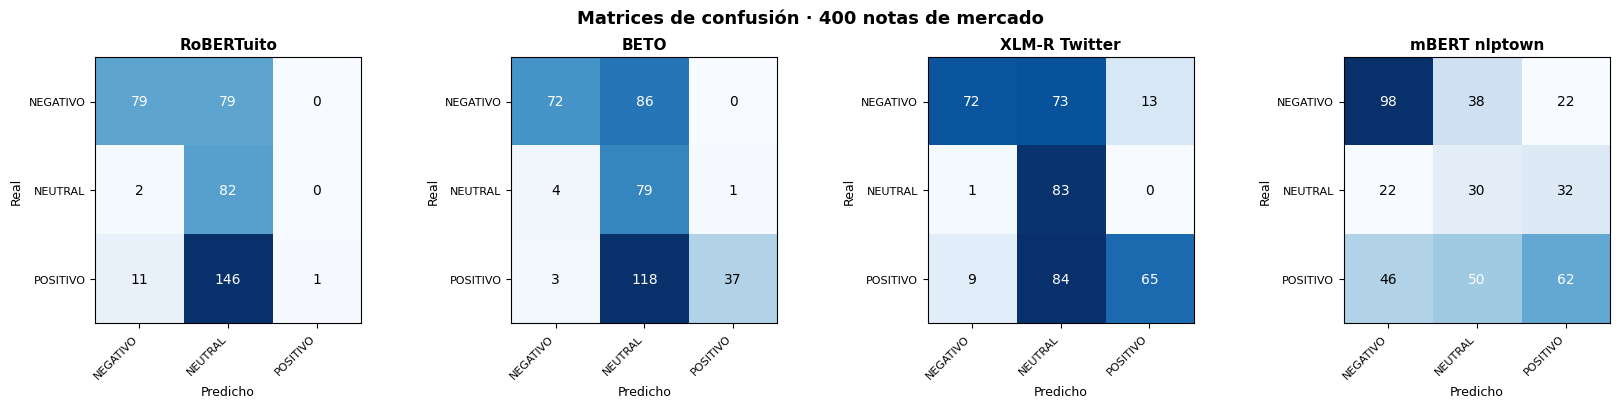

In [13]:
# Matrices de confusión
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, len(MODELOS), figsize=(4.2*len(MODELOS), 4))
for eje, m in zip(ejes, MODELOS):
    cm = matrices[m["alias"]]
    eje.imshow(cm, cmap="Blues")
    eje.set_title(m["alias"], fontsize=11, fontweight="bold")
    eje.set_xticks(range(3)); eje.set_xticklabels(CLASES, rotation=45, ha="right", fontsize=8)
    eje.set_yticks(range(3)); eje.set_yticklabels(CLASES, fontsize=8)
    eje.set_xlabel("Predicho", fontsize=9); eje.set_ylabel("Real", fontsize=9)
    umbral = cm.max() / 2
    for i in range(3):
        for j in range(3):
            eje.text(j, i, cm[i, j], ha="center", va="center", fontsize=10,
                     color="white" if cm[i, j] > umbral else "black")
plt.suptitle("Matrices de confusión · 400 notas de mercado", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("matrices_confusion.png", dpi=140, bbox_inches="tight")
plt.show()

---
## 8. Tabla comparativa consolidada

Precisión y eficiencia en una sola vista. Esta es la tabla que va al documento.

In [14]:
# Celda 8 — tabla comparativa
comparativa = (pd.DataFrame(resultados)
               .merge(metricas, left_on="alias", right_on="modelo")
               [["alias", "familia", "arquitectura", "parametros_M", "licencia",
                 "accuracy", "precision_macro", "recall_macro", "f1_macro",
                 "ms_por_nota_lote", "ms_unitaria_media", "notas_por_s", "carga_s"]]
               .sort_values("f1_macro", ascending=False)
               .reset_index(drop=True))

comparativa.columns = ["Modelo", "Familia", "Arquitectura", "Parámetros (M)",
                       "Licencia", "Accuracy", "Precision macro", "Recall macro",
                       "F1 macro", "ms/nota (lote)", "ms unitaria", "notas/s",
                       "Carga (s)"]
print(comparativa.to_string(index=False))
comparativa.to_csv("tabla_comparativa.csv", index=False)
comparativa

       Modelo            Familia         Arquitectura  Parámetros (M)   Licencia  Accuracy  Precision macro  Recall macro  F1 macro  ms/nota (lote)  ms unitaria  notas/s  Carga (s)
XLM-R Twitter        Multilingüe     XLM-RoBERTa base           278.0        MIT     0.550           0.6857        0.6184    0.5544            3.02         21.9    330.8       21.6
         BETO Español específico          BERT (BETO)           109.9 Apache-2.0     0.470           0.7214        0.5434    0.4719            6.31         20.4    158.5       12.2
mBERT nlptown        Multilingüe     BERT multilingüe           167.4        MIT     0.475           0.4597        0.4566    0.4515            3.04         10.6    329.4       15.4
   RoBERTuito Español específico RoBERTa (RoBERTuito)           108.8 Apache-2.0     0.405           0.7086        0.4942    0.3547            2.98         23.7    335.4       12.0


,Modelo,Familia,Arquitectura,Parámetros (M),Licencia,Accuracy,Precision macro,Recall macro,F1 macro,ms/nota (lote),ms unitaria,notas/s,Carga (s)
0,XLM-R Twitter,Multilingüe,XLM-RoBERTa base,278.0,MIT,0.550,0.6857,0.6184,0.5544,3.02,21.9,330.8,21.6
1,BETO,Español específico,BERT (BETO),109.9,Apache-2.0,0.470,0.7214,0.5434,0.4719,6.31,20.4,158.5,12.2
2,mBERT nlptown,Multilingüe,BERT multilingüe,167.4,MIT,0.475,0.4597,0.4566,0.4515,3.04,10.6,329.4,15.4
3,RoBERTuito,Español específico,RoBERTa (RoBERTuito),108.8,Apache-2.0,0.405,0.7086,0.4942,0.3547,2.98,23.7,335.4,12.0


---
## 9. Análisis de errores: dónde se rompe cada modelo

Aquí es donde la comparación deja de ser un concurso de números. El corpus trae
marcada la dificultad de cada nota y el fenómeno lingüístico que la hace difícil.
Lo que me interesa saber no es cuál modelo acierta más en promedio, sino **cuál
falla en las notas que de verdad importan**: las que llevan una negación.

En el negocio esto es concreto. «El banco central **no** modificará la tasa» es
una buena noticia para los fondos de deuda de corto plazo. Un modelo que lea la
palabra «no» y marque la nota como negativa va a esconderle al asesor una
oportunidad real, o peor, va a sugerir salirse de un fondo que iba a rendir bien.

In [15]:
# Celda 9 — desempeño por dificultad y por fenómeno lingüístico
from sklearn.metrics import f1_score

detalle = []
for m in MODELOS:
    alias = m["alias"]
    tmp = df.copy()
    tmp["pred"] = predicciones[alias]["pred"]
    fila = {"modelo": alias}
    for d in ["facil", "media", "dificil"]:
        s = tmp[tmp.dificultad == d]
        fila[f"F1_{d}"] = round(f1_score(s.impacto, s.pred, average="macro",
                                         zero_division=0), 3)
    for fen in ["negacion", "contraste"]:
        s = tmp[tmp.fenomeno == fen]
        fila[f"acc_{fen}"] = round((s.impacto == s.pred).mean(), 3)
    detalle.append(fila)

por_dificultad = pd.DataFrame(detalle)
print("F1 macro por nivel de dificultad y exactitud en los fenómenos críticos\n")
print(por_dificultad.to_string(index=False))
por_dificultad.to_csv("desempeno_por_dificultad.csv", index=False)

F1 macro por nivel de dificultad y exactitud en los fenómenos críticos

       modelo  F1_facil  F1_media  F1_dificil  acc_negacion  acc_contraste
   RoBERTuito     0.357     0.226       0.248         0.365          0.246
         BETO     0.498     0.366       0.339         0.392          0.298
XLM-R Twitter     0.519     0.579       0.358         0.405          0.509
mBERT nlptown     0.467     0.302       0.351         0.527          0.351


In [16]:
# Ejemplos concretos de error en notas con negación (el caso que más me preocupa)
mejor = metricas.iloc[0]["modelo"]
tmp = df.copy()
tmp["pred"] = predicciones[mejor]["pred"]
tmp["conf"] = predicciones[mejor]["conf"]
fallos = tmp[(tmp.fenomeno == "negacion") & (tmp.impacto != tmp.pred)]

print(f"Modelo con mejor F1 macro: {mejor}")
print(f"Notas con negación mal clasificadas: {len(fallos)} de "
      f"{(tmp.fenomeno=='negacion').sum()}\n")
for _, f in fallos.head(6).iterrows():
    print(f"  real={f.impacto:8s}  pred={f.pred:8s}  conf={f.conf:.2f}")
    print(f"     {f.texto[:140]}\n")

Modelo con mejor F1 macro: XLM-R Twitter
Notas con negación mal clasificadas: 44 de 74

  real=POSITIVO  pred=NEUTRAL   conf=0.57
     Nota de la mesa de análisis: La inflación subyacente no sorprendió al alza y se mantuvo dentro del rango objetivo. El equipo de inversiones 

  real=POSITIVO  pred=NEUTRAL   conf=0.59
     La agencia no degradó la calificación soberana y el tipo de cambio recuperó terreno.

  real=POSITIVO  pred=NEGATIVO  conf=0.78
     Nota de la mesa de análisis: La calificadora no modificó la nota soberana y retiró la perspectiva negativa que mantenía desde el año pasado.

  real=POSITIVO  pred=NEUTRAL   conf=0.77
     La empresa no recortó su dividendo pese al entorno y confirmó el calendario de pago.

  real=POSITIVO  pred=NEUTRAL   conf=0.50
     Nota de la mesa de análisis: La inflación subyacente no sorprendió al alza y se mantuvo dentro del rango objetivo.

  real=POSITIVO  pred=NEUTRAL   conf=0.45
     Comentario semanal: La inflación subyacente no sorprendió 

---
## 10. Equilibrio entre precisión y eficiencia

La pregunta práctica no es cuál modelo es mejor, sino cuál conviene **dado el
volumen del caso de uso**. El motor procesa alrededor de 250 notas al día para
los 24 asesores del alcance. A ese volumen, una diferencia de 20 ms por nota son
5 segundos al día: irrelevante. Lo que no es irrelevante es un punto de F1.

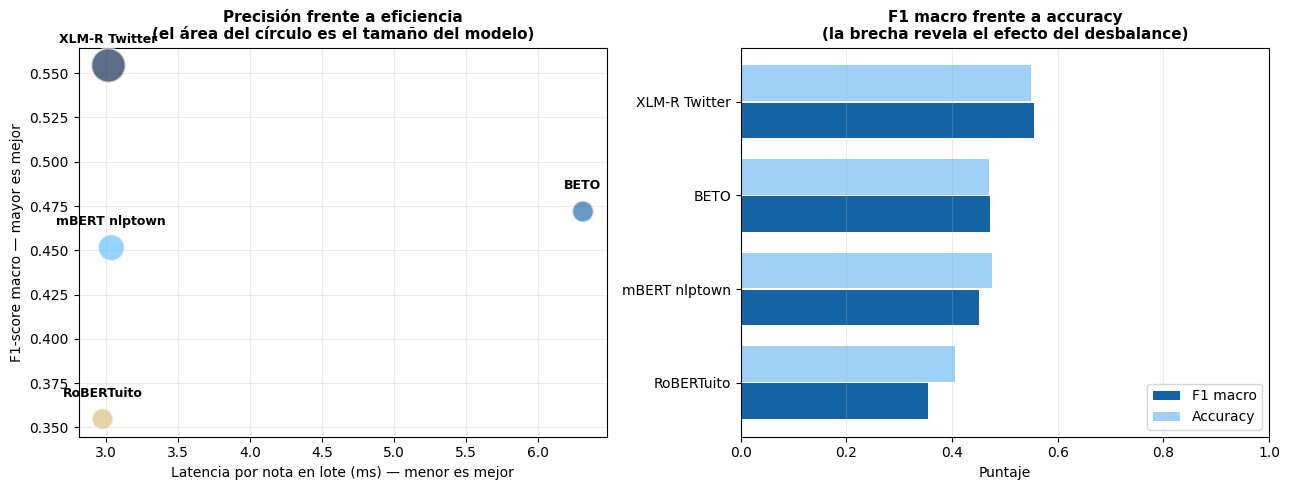

In [17]:
# Celda 10 — gráfico de trade-off
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.scatter(comparativa["ms/nota (lote)"], comparativa["F1 macro"],
            s=comparativa["Parámetros (M)"]*2.2, alpha=.65,
            c=["#072146", "#1464A5", "#5BBEFF", "#D8BE75"][:len(comparativa)],
            edgecolors="white", linewidth=1.6, zorder=3)
for _, r in comparativa.iterrows():
    ax1.annotate(r["Modelo"], (r["ms/nota (lote)"], r["F1 macro"]),
                 textcoords="offset points", xytext=(0, 16),
                 ha="center", fontsize=9, fontweight="bold")
ax1.set_xlabel("Latencia por nota en lote (ms) — menor es mejor")
ax1.set_ylabel("F1-score macro — mayor es mejor")
ax1.set_title("Precisión frente a eficiencia\n(el área del círculo es el tamaño del modelo)",
              fontsize=11, fontweight="bold")
ax1.grid(alpha=.25, zorder=0)

x = range(len(comparativa))
ax2.barh([i+0.2 for i in x], comparativa["F1 macro"], height=.38,
         color="#1464A5", label="F1 macro")
ax2.barh([i-0.2 for i in x], comparativa["Accuracy"], height=.38,
         color="#9FD0F5", label="Accuracy")
ax2.set_yticks(list(x)); ax2.set_yticklabels(comparativa["Modelo"])
ax2.invert_yaxis(); ax2.set_xlim(0, 1)
ax2.set_xlabel("Puntaje")
ax2.set_title("F1 macro frente a accuracy\n(la brecha revela el efecto del desbalance)",
              fontsize=11, fontweight="bold")
ax2.legend(loc="lower right"); ax2.grid(axis="x", alpha=.25)

plt.tight_layout()
plt.savefig("tradeoff_precision_latencia.png", dpi=140, bbox_inches="tight")
plt.show()

---
## 11. Ajustes mínimos

El Tema 10 define los ajustes mínimos como configuraciones sobre el modelo
preentrenado que lo alinean al caso de uso **sin reentrenarlo**. Apliqué tres,
en orden de costo creciente:

1. **Mapeo de etiquetas** (ya aplicado en la celda 5). Llevar POS/NEU/NEG,
   Negative/Neutral/Positive y la escala de 5 estrellas a un vocabulario único.
2. **Normalización del texto.** Las notas traen prefijos de la mesa
   («Flash informativo:», «Cierre de mercado:») que no aportan señal de impacto.
3. **Umbral de confianza con abstención.** Si el modelo no está suficientemente
   seguro, el motor no emite señal y la nota pasa a revisión del asesor. Esto es
   supervisión humana efectiva, y en banca no es opcional.

El tercero es el relevante para el negocio, así que lo mido: cuánta exactitud
gano a cambio de cuánta cobertura pierdo.

In [18]:
# Celda 11 — efecto del umbral de confianza
mejor = metricas.iloc[0]["modelo"]
pred = np.array(predicciones[mejor]["pred"])
conf = np.array(predicciones[mejor]["conf"])
real = np.array(VERDADES)

filas_umbral = []
for u in [0.00, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]:
    acepta = conf >= u
    cobertura = acepta.mean()
    exactitud = (pred[acepta] == real[acepta]).mean() if acepta.any() else float("nan")
    filas_umbral.append({
        "umbral": u,
        "cobertura_%": round(100*cobertura, 1),
        "notas_automaticas": int(acepta.sum()),
        "notas_a_revision": int((~acepta).sum()),
        "exactitud_en_aceptadas_%": round(100*exactitud, 1),
    })

umbrales = pd.DataFrame(filas_umbral)
print(f"Modelo evaluado: {mejor}\n")
print(umbrales.to_string(index=False))
umbrales.to_csv("curva_umbral.csv", index=False)

Modelo evaluado: XLM-R Twitter

 umbral  cobertura_%  notas_automaticas  notas_a_revision  exactitud_en_aceptadas_%
   0.00        100.0                400                 0                      55.0
   0.50         89.0                356                44                      56.7
   0.60         63.5                254               146                      61.4
   0.70         34.8                139               261                      77.7
   0.80         13.2                 53               347                      77.4
   0.90          0.0                  0               400                       NaN
   0.95          0.0                  0               400                       NaN


In [19]:
# Normalización de texto: ¿los prefijos de la mesa afectan la predicción?
import re
PREFIJOS_MESA = re.compile(
    r"^(?:Nota de la mesa de análisis|Resumen diario de mercados|Flash informativo|"
    r"Cierre de mercado|Comentario semanal):\s*", re.IGNORECASE)

con_prefijo = df.texto.str.contains(PREFIJOS_MESA, regex=True, na=False)
print(f"Notas con prefijo de mesa: {con_prefijo.sum()} de {len(df)}")

tmp = df.copy()
tmp["pred"] = predicciones[mejor]["pred"]
print(f"\nExactitud de {mejor}:")
print(f"  con prefijo : {(tmp[con_prefijo].impacto == tmp[con_prefijo].pred).mean():.3f}")
print(f"  sin prefijo : {(tmp[~con_prefijo].impacto == tmp[~con_prefijo].pred).mean():.3f}")
print("\nSi la diferencia es material, conviene limpiar el prefijo antes de inferir.")

Notas con prefijo de mesa: 238 de 400

Exactitud de XLM-R Twitter:
  con prefijo : 0.546
  sin prefijo : 0.556

Si la diferencia es material, conviene limpiar el prefijo antes de inferir.


---
## 12. Conclusiones parciales

> Esta celda se llena **después** de ejecutar el cuaderno, con los números que
> arroje tu corrida. La redacto como lista de preguntas a contestar para que las
> conclusiones salgan de la evidencia y no al revés.

1. **¿Qué modelo gana en F1 macro y por cuánto?** Si la diferencia frente al
   segundo es menor a 2 puntos, la decisión debería resolverse por latencia,
   licencia o tamaño, no por precisión.
2. **¿Ganó un modelo en español o un multilingüe?** Esta es la hipótesis central
   del experimento.
3. **¿Cuánto cae el F1 en las notas con negación frente a las directas?** Es el
   riesgo operativo concreto del motor.
4. **¿Qué tan grande es la brecha entre accuracy y F1 macro?** Una brecha amplia
   confirma que el modelo se apoya en la clase mayoritaria.
5. **¿A qué umbral de confianza la exactitud supera el 90 % y cuánta cobertura
   cuesta?** De ahí sale la regla de operación del motor.

In [20]:
# Celda 12 — exportación de evidencia y resumen final
import json, datetime, shutil, os

os.makedirs("resultados", exist_ok=True)
for archivo in ["tabla_comparativa.csv", "desempeno_por_dificultad.csv",
                "curva_umbral.csv", "matrices_confusion.png",
                "tradeoff_precision_latencia.png"]:
    if os.path.exists(archivo):
        shutil.move(archivo, os.path.join("resultados", archivo))

# predicciones completas, para auditoría
salida = df.copy()
for m in MODELOS:
    salida[f"pred_{m['alias']}"] = predicciones[m["alias"]]["pred"]
    salida[f"conf_{m['alias']}"] = [round(c, 4) for c in predicciones[m["alias"]]["conf"]]
salida.to_csv("resultados/predicciones_completas.csv", index=False)

entorno = {
    "fecha_ejecucion": datetime.datetime.now().isoformat(timespec="seconds"),
    "gpu": torch.cuda.get_device_name(0) if HAY_GPU else "CPU",
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "registros": len(df),
    "modelos": [m["id"] for m in MODELOS],
    "semilla_dataset": 20261008,
}
with open("resultados/condiciones_ejecucion.json", "w", encoding="utf-8") as fh:
    json.dump(entorno, fh, indent=2, ensure_ascii=False)

print("Archivos exportados en ./resultados :")
for a in sorted(os.listdir("resultados")):
    print("  -", a)

print("\n" + "="*72)
print("TABLA PARA PEGAR EN EL DOCUMENTO")
print("="*72)
print(comparativa.to_string(index=False))
print("\n" + "="*72)
print("DESEMPEÑO POR DIFICULTAD")
print("="*72)
print(por_dificultad.to_string(index=False))
print("\n" + "="*72)
print("CURVA DE UMBRAL")
print("="*72)
print(umbrales.to_string(index=False))

Archivos exportados en ./resultados :
  - condiciones_ejecucion.json
  - curva_umbral.csv
  - desempeno_por_dificultad.csv
  - matrices_confusion.png
  - predicciones_completas.csv
  - tabla_comparativa.csv
  - tradeoff_precision_latencia.png

TABLA PARA PEGAR EN EL DOCUMENTO
       Modelo            Familia         Arquitectura  Parámetros (M)   Licencia  Accuracy  Precision macro  Recall macro  F1 macro  ms/nota (lote)  ms unitaria  notas/s  Carga (s)
XLM-R Twitter        Multilingüe     XLM-RoBERTa base           278.0        MIT     0.550           0.6857        0.6184    0.5544            3.02         21.9    330.8       21.6
         BETO Español específico          BERT (BETO)           109.9 Apache-2.0     0.470           0.7214        0.5434    0.4719            6.31         20.4    158.5       12.2
mBERT nlptown        Multilingüe     BERT multilingüe           167.4        MIT     0.475           0.4597        0.4566    0.4515            3.04         10.6    329.4       15.4

---

**Eduardo Aburto Angulo** · Banquero Patrimonial Sr., BBVA México · plaza Xalapa
Matrícula AL07182743 · Universidad Tecmilenio

*La inteligencia artificial no sustituye el criterio del banquero; lo aumenta.*